## 工具白名单 —— 限制Agent能做什么 -> 最小权限

In [6]:
import inspect
from deepagents.middleware import FilesystemMiddleware
for name, param in inspect.signature(FilesystemMiddleware.__init__).parameters.items():
    print(name, param)

self self
backend backend: deepagents.backends.protocol.BackendProtocol | None = None
system_prompt system_prompt: str | None = None
custom_tool_descriptions custom_tool_descriptions: collections.abc.Mapping[str, str] | None = None
tool_token_limit_before_evict tool_token_limit_before_evict: int | None = 20000
human_message_token_limit_before_evict human_message_token_limit_before_evict: int | None = 50000
max_execute_timeout max_execute_timeout: int = 3600
grep_max_count grep_max_count: int | None = 1000
tools tools: Union[list[Literal['ls', 'read_file', 'write_file', 'edit_file', 'delete', 'glob', 'grep', 'execute']], Literal['all'], NoneType] = None
_permissions _permissions: list[deepagents.middleware.filesystem.FilesystemPermission] | None = None



| 参数 | 类型 | 默认 | 作用 |
| :--- | :--- | :--- | :--- |
| `backend` | `BackendProtocol` \| `None` | `None` | 文件存哪、怎么读写、是否支持 execute |
| `system_prompt` | `str` \| `None` | `None` | 覆盖文件系统系统提示 |
| `custom_tool_descriptions` | `Mapping[str,str]` \| `None` | `None` | 按工具名覆盖工具描述 |
| `tool_token_limit_before_evict` | `int` \| `None` | `20000` | 工具结果超阈值落盘 |
| `human_message_token_limit_before_evict` | `int` \| `None` | `50000` | 人类消息超阈值落盘/驱逐 |
| `max_execute_timeout` | `int` | `3600` | `execute` 命令超时（秒） |
| `grep_max_count` | `int` \| `None` | `1000` | `grep` 最大返回匹配数 |
| `tools` | `list[ToolName]` \| `'all'` \| `None` | `None` | 启用哪些文件工具 |
| `_permissions` | `list[FilesystemPermission]` \| `None` | `None` | 路径/操作级权限控制 |

`FilesystemMiddleware` 中 `tools` 作用：显示选择注册哪些工具，实现最小权限工具集

In [7]:
# 工具白名单使用方法
# FilesystemMiddleware 工具白名单
from deepagents import create_deep_agent
from deepagents.middleware import FilesystemMiddleware
from deepagents.backends import StateBackend
from models1 import build_model_deepseek

def tool_whitelist_case():
    # 1. 中间件：关键字参数传入
    middleware = FilesystemMiddleware(
        backend=StateBackend(),
        tools=["read_file", "ls"]   # 白名单：只读工具
    )

    agent = create_deep_agent(
        model=build_model_deepseek(),
        middleware=[middleware],
        system_prompt="你只能使用 read_file 和 ls 工具。"
    )

    result = agent.invoke({
        "messages": [{
            "role": "user",
            "content": "请创建一个名为 test.txt 的文件，内容为 'hello'。"
        }]
    })
    print("Agent 回答：", result["messages"][-1].content)

In [8]:
tool_whitelist_case()

Agent 回答： 我无法完成这个操作：我当前可用的工具只有 `ls`（列目录）和 `read_file`（读文件），都是只读的，没有任何写入、编辑或执行命令的能力。因此我无法创建 `test.txt`。

顺带一提，我列了一下根目录 `/`，返回为空，看不到任何文件。

你可以自己执行以下任一命令来创建该文件：

**Linux / macOS（bash）**
```bash
printf 'hello' > test.txt
```

**Windows（PowerShell）**
```powershell
Set-Content -Path test.txt -Value 'hello' -NoNewline
```

如果你希望文件末尾带换行符，把 `printf` 换成 `echo` 即可。

如果你愿意，我可以在你创建好之后帮你读取并确认内容是否正确。


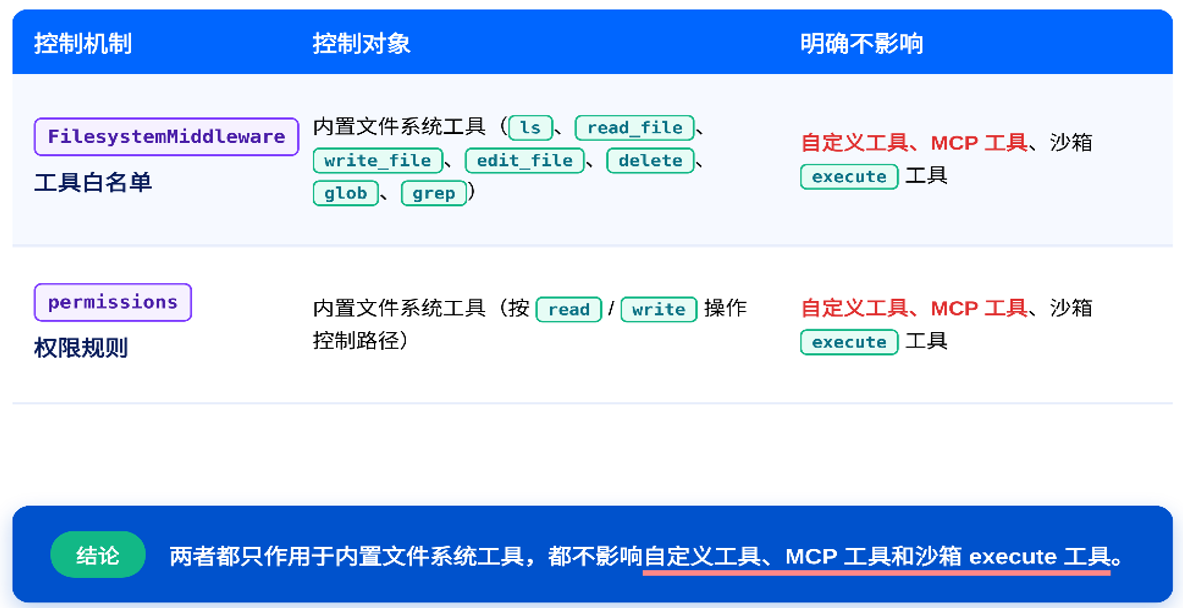